# HLO Ontology Training

**Run:** select a GPU runtime, run all cells, and upload `HLO-Colab-Project.zip` when prompted. This notebook calls the project's `tools/train_hlo.py` and uses the original `configs/mt5.toml`.

**Scope:** direct-parent retrieval from the HLO OWL graph. The generated split contains 1,922 training, 642 validation, and 642 test questions.


In [ ]:
from pathlib import Path
import os
import sys

WORKSPACE = Path(os.environ.get("HLO_COLAB_WORKSPACE", "/content")).resolve()
PROJECT_ZIP = WORKSPACE / "HLO-Colab-Project.zip"
if not PROJECT_ZIP.exists():
    PROJECT_ZIP = WORKSPACE / "HLO-recommendation-system-main(1).zip"
OUTPUT_ROOT = WORKSPACE / "hlo-runs"

TRAIN_MODEL = True
WANDB_MODE = "offline"  # offline | online | disabled
WANDB_PROJECT = "hlo-recommendation"
WANDB_ENTITY = None


## 1. Upload the project and view the workflow

The project archive includes the data-generation and training diagrams. Set `TRAIN_MODEL = False` to run validation and the SPARQL baseline without a GPU.


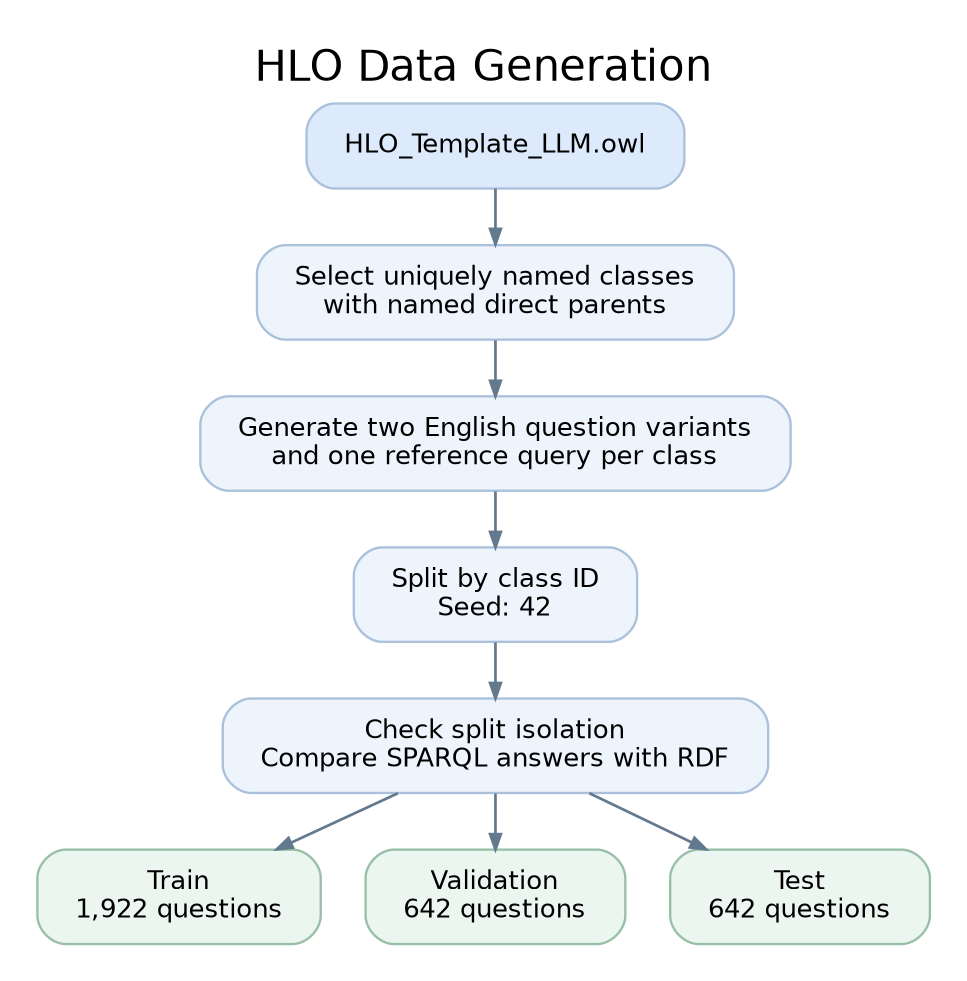

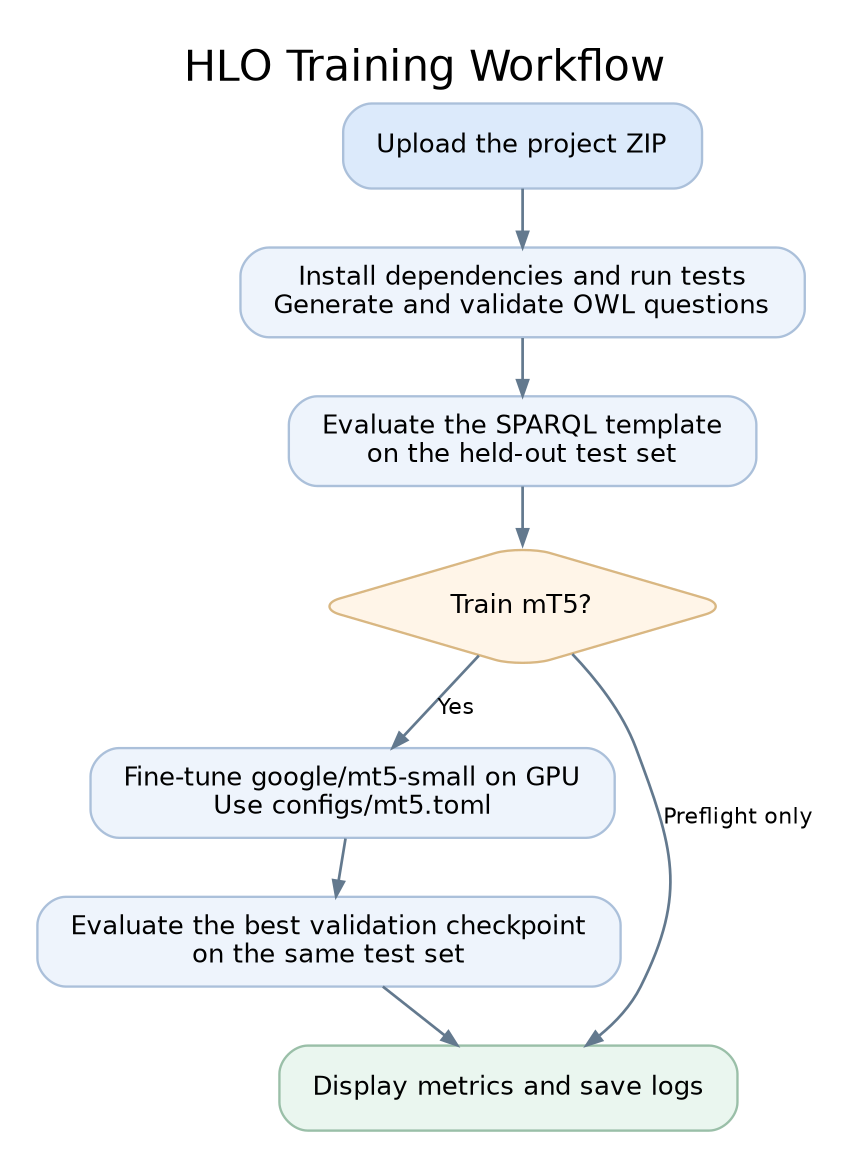

In [2]:
from tempfile import mkdtemp
from zipfile import ZipFile
from pathlib import PurePosixPath
import stat

WORKSPACE.mkdir(parents=True, exist_ok=True)
if not PROJECT_ZIP.is_file():
    from google.colab import files

    uploaded = files.upload()
    zip_files = [(name, content) for name, content in uploaded.items() if name.lower().endswith(".zip")]
    if len(zip_files) != 1:
        raise ValueError("Upload one project ZIP.")
    name, contents = zip_files[0]
    upload_dir = Path(mkdtemp(prefix="hlo-upload-", dir=WORKSPACE))
    PROJECT_ZIP = upload_dir / Path(name).name
    PROJECT_ZIP.write_bytes(contents)
    del uploaded, zip_files, contents

extract_dir = Path(mkdtemp(prefix="hlo-source-", dir=WORKSPACE)).resolve()
with ZipFile(PROJECT_ZIP) as archive:
    for entry in archive.infolist():
        name = PurePosixPath(entry.filename)
        mode = (entry.external_attr >> 16) & 0xFFFF
        if (name.is_absolute() or ".." in name.parts or "\\" in entry.filename
                or stat.S_ISLNK(mode) or not (extract_dir / name).resolve().is_relative_to(extract_dir)):
            raise ValueError(f"Unsafe path in ZIP: {entry.filename}")
    archive.extractall(extract_dir)

projects = sorted(
    path.parent for path in extract_dir.rglob("pyproject.toml")
    if (path.parent / "tools/train_hlo.py").is_file()
    and (path.parent / "configs/mt5.toml").is_file()
    and (path.parent / "data/ontology/HLO_Template_LLM.owl").is_file()
)
if len(projects) != 1:
    raise ValueError("Expected one HLO project in the archive.")
PROJECT = projects[0]
print("Project:", PROJECT)
for filename in ("data-generation.png", "main-workflow.png"):
    diagram = PROJECT / "docs/colab" / filename
    if diagram.is_file():
        from IPython.display import Image, display
        display(Image(filename=str(diagram), width=680))


## 2. Run training or preflight

The original runner generates and validates the OWL data, evaluates the template, and trains and evaluates mT5 when enabled. W&B uses `offline` by default. For `online`, add `WANDB_API_KEY` to Colab Secrets.


In [ ]:
import subprocess
from datetime import datetime, timezone

if WANDB_MODE not in {"offline", "online", "disabled"}:
    raise ValueError("WANDB_MODE must be offline, online, or disabled.")
if TRAIN_MODEL:
    subprocess.run(
        [sys.executable, "-c",
         "import torch; assert torch.cuda.is_available(), 'Enable a GPU in Colab'; print(torch.cuda.get_device_name(0))"],
        check=True,
    )

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
SESSION_DIR = OUTPUT_ROOT / stamp
SESSION_DIR.mkdir(parents=True)
constraints = SESSION_DIR / "colab-constraints.txt"
constraints.write_text("torch>=2.6,<3\nsentencepiece>=0.2,<0.2.2\n", encoding="utf-8")
env = {**os.environ, "PIP_CONSTRAINT": str(constraints), "PYTHONUNBUFFERED": "1"}

if WANDB_MODE == "online" and not env.get("WANDB_API_KEY"):
    from google.colab import userdata

    env["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    if not env["WANDB_API_KEY"]:
        raise ValueError("Add WANDB_API_KEY to Colab Secrets.")

if WANDB_MODE != "disabled":
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-e", ".[tracking]"],
        cwd=PROJECT, env=env, check=True,
    )

command = [
    sys.executable, "-u", "tools/train_hlo.py",
    "--project", str(PROJECT), "--output", str(SESSION_DIR),
    "--wandb-mode", WANDB_MODE, "--wandb-project", WANDB_PROJECT,
]
if WANDB_ENTITY:
    command.extend(["--wandb-entity", WANDB_ENTITY])
if not TRAIN_MODEL:
    command.append("--check-only")

print("Run directory:", SESSION_DIR, flush=True)
completed = subprocess.run(command, cwd=PROJECT, env=env)
if completed.returncode:
    print("Review hlo-training.log. The next cell can show saved results.")
    completed.check_returncode()


## 3. Review the results

The table reads the saved metrics from the current run. Training curves appear when mT5 writes an epoch history.

Saved output below is from the verified CPU preflight. Rerun the cells to replace it with your results.


In [4]:
import json
from IPython.display import display, Markdown

run_folders = sorted(path for path in SESSION_DIR.glob("hlo-*") if path.is_dir())
if len(run_folders) != 1:
    raise FileNotFoundError(f"Expected one run directory under {SESSION_DIR}")
RUN_DIR = run_folders[0]

summary_path = RUN_DIR / "run-summary.json"
if not summary_path.is_file():
    raise FileNotFoundError(f"The run summary is missing. Review: {RUN_DIR / 'hlo-training.log'}")
summary = json.loads(summary_path.read_text(encoding="utf-8"))
print("Status:", summary["status"])
print("Training log:", RUN_DIR / "hlo-training.log")
print("Run summary:", summary_path)

manifest = RUN_DIR / "ontology-data/manifest.json"
if manifest.is_file():
    print("Ontology splits:")
    print(json.dumps(json.loads(manifest.read_text(encoding="utf-8"))["questions"], indent=2))

lines = ["| Generator | Test questions | Execution validity | Answer F1 |",
         "| --- | ---: | ---: | ---: |"]
for name, metrics in summary.get("query_metrics", {}).items():
    lines.append(f"| {name} | {metrics['n']:,} | {metrics['valid_rate']:.1%} | {metrics['answer_f1']:.3f} |")
if len(lines) > 2:
    display(Markdown("\n".join(lines)))
else:
    print("No test metrics were written.")
if "mt5" not in summary.get("query_metrics", {}):
    print("mT5 test metrics are unavailable for this run.")
print("W&B status:", summary.get("wandb", {}).get("status", "unknown"))

checkpoint = RUN_DIR / "mt5/checkpoint"
if checkpoint.is_dir():
    print("Model checkpoint:", checkpoint)
    print("Complete archive:", RUN_DIR.with_suffix(".zip"))

history_path = RUN_DIR / "mt5/history.json"
if history_path.is_file():
    import matplotlib.pyplot as plt

    history = json.loads(history_path.read_text(encoding="utf-8"))
    if history:
        epochs = [record["epoch"] for record in history]
        fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
        axes[0].plot(epochs, [r["train_loss"] for r in history], "o-")
        axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
        axes[1].plot(epochs, [r["validation"]["answer_f1"] for r in history], "o-", label="Answer F1")
        axes[1].plot(epochs, [r["validation"]["valid_rate"] for r in history], "s--", label="Validity")
        axes[1].set(title="Validation metrics", xlabel="Epoch", ylim=(-0.02, 1.02))
        axes[1].legend()
        plt.show()


Verified CPU preflight | 20/20 unit tests passed | W&B offline: finished
Generated 3,206 OWL-derived questions: 1,922 train, 642 validation, 642 test.


| Generator | Test questions | Execution validity | Answer F1 |
| --- | ---: | ---: | ---: |
| template | 642 | 100.0% | 1.000 |


mT5 training and test evaluation were skipped in this preflight.


## 4. Download logs
Set `DOWNLOAD_LOGS = True` to download a compact results ZIP.


In [ ]:
from zipfile import ZIP_DEFLATED

DOWNLOAD_LOGS = False
if DOWNLOAD_LOGS:
    from google.colab import files

    export_path = RUN_DIR.with_name(RUN_DIR.name + "-results.zip")
    candidates = (
        "hlo-training.log", "hlo-events.jsonl", "run-summary.json",
        "ontology-data/manifest.json", "mt5/history.json", "mt5/checkpoint/manifest.json",
        "evaluation/template/metrics.json", "evaluation/mt5/metrics.json",
        "evaluation/bkt/metrics.json",
    )
    with ZipFile(export_path, "w", ZIP_DEFLATED) as archive:
        for name in candidates:
            path = RUN_DIR / name
            if path.is_file():
                archive.write(path, arcname=name)
    files.download(str(export_path))
